<div style="background-color: #0f172a; color: #f8fafc; padding: 28px 32px; border-radius: 8px; border-left: 6px solid #2563eb; font-family: 'Segoe UI', Arial, sans-serif;">
    <p style="margin: 0; font-size: 12px; letter-spacing: 1.5px; text-transform: uppercase; color: #93c5fd; font-weight: 600;">Processo Seletivo - Ciencia de Dados &amp; Machine Learning</p>
    <h1 style="margin: 8px 0 12px 0; font-size: 28px; font-weight: 700; color: #ffffff;">Atividade Somativa 1: Modelagem Preditiva de Desempenho na NBA</h1>
    <p style="margin: 0; font-size: 15px; line-height: 1.6; color: #cbd5e1;">
        Este documento apresenta o desenvolvimento completo de uma solucao de Machine Learning aplicada ao dataset historico de jogadores da NBA (1950 a 2017). 
        O objetivo central e prever a metrica <strong>WinShares</strong> (estimativa da contribuicao de um jogador em vitorias da sua equipe) a partir de suas estatisticas individuais em quadra.
    </p>
</div>

<div style="margin-top: 18px; padding: 16px 20px; background-color: #f8fafc; border: 1px solid #e2e8f0; border-radius: 6px; font-family: 'Segoe UI', Arial, sans-serif;">
    <h3 style="margin-top: 0; color: #1e293b; font-size: 16px;">Roteiro Metodologico</h3>
    <ol style="margin-bottom: 0; color: #334155; font-size: 14px; line-height: 1.7;">
        <li><strong>Carregamento e Exploracao dos Dados:</strong> Leitura do arquivo original e diagnostico da estrutura da base.</li>
        <li><strong>Preparacao dos Dados:</strong> Tratamento de valores ausentes, prevencao de vazamento de dados e codificacao de categorias.</li>
        <li><strong>Selecao de Atributos:</strong> Aplicacao de tecnica estatistica para identificar e manter apenas as variaveis mais relevantes.</li>
        <li><strong>Definicao do Problema:</strong> Enquadramento formal da tarefa preditiva e justificativa tecnica.</li>
        <li><strong>Divisao Treino e Teste (75% / 25%):</strong> Separacao rigorosa para avaliacao imparcial do algoritmo.</li>
        <li><strong>Treinamento e Predicao:</strong> Construcao de modelo supervisionado com Scikit-Learn e analise dos resultados obtidos.</li>
    </ol>
</div>

<div style="border-bottom: 2px solid #2563eb; padding-bottom: 6px; margin-top: 24px; font-family: 'Segoe UI', Arial, sans-serif;">
    <h2 style="margin: 0; color: #0f172a; font-size: 20px;">1. Configuracao do Ambiente e Carregamento do Dataset</h2>
</div>
<p style="font-family: 'Segoe UI', Arial, sans-serif; color: #334155; font-size: 14px; line-height: 1.6; margin-top: 10px;">
    Nesta primeira etapa, carregamos as bibliotecas necessarias para manipulacao de tabelas (<strong>pandas</strong>), calculos numericos (<strong>numpy</strong>), visualizacao grafica (<strong>matplotlib</strong> e <strong>seaborn</strong>) e algoritmos de inteligencia artificial (<strong>scikit-learn</strong>). 
    Em termos praticos, isso equivale a organizar todas as ferramentas de trabalho antes de iniciar a analise da base de dados <code>nba_stats.csv</code>.
</p>

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

# Configuracao visual padrao para os graficos
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.edgecolor'] = '#cbd5e1'
plt.rcParams['axes.linewidth'] = 0.8
sns.set_style('whitegrid')

# Carregamento do dataset disponibilizado
df_raw = pd.read_csv('nba_stats.csv')

print(f'Dataset carregado com sucesso.')
print(f'Dimensoes originais: {df_raw.shape[0]:,} registros (linhas) e {df_raw.shape[1]} atributos (colunas).')

Dataset carregado com sucesso.
Dimensoes originais: 24,624 registros (linhas) e 22 atributos (colunas).


<div style="border-bottom: 2px solid #2563eb; padding-bottom: 6px; margin-top: 24px; font-family: 'Segoe UI', Arial, sans-serif;">
    <h2 style="margin: 0; color: #0f172a; font-size: 20px;">2. Analise Exploratoria Inicial</h2>
</div>
<p style="font-family: 'Segoe UI', Arial, sans-serif; color: #334155; font-size: 14px; line-height: 1.6; margin-top: 10px;">
    Antes de aplicar qualquer tecnica de Machine Learning, e essencial inspecionar a qualidade dos dados. 
    Abaixo, visualizamos as primeiras linhas da tabela, os tipos de informacao presentes (numeros ou textos) e a quantidade de campos em branco (valores ausentes) em cada coluna.
</p>

In [2]:
# Visualizacao das 5 primeiras linhas do dataset
display(df_raw.head())

# Diagnostico de tipos de dados e valores ausentes
diagnostico = pd.DataFrame({
    'Tipo_Dado': df_raw.dtypes,
    'Valores_Ausentes': df_raw.isnull().sum(),
    'Percentual_Ausentes (%)': (df_raw.isnull().sum() / len(df_raw) * 100).round(2),
    'Valores_Unicos': df_raw.nunique()
})

print('\nResumo estrutural das colunas:')
display(diagnostico)

,Ano,Posicao,Idade,Jogos,TrueShootingPercentage,FreeThrowRate,OffensiveWinShares,DefensiveWinShares,WinShares,FieldGoals,...,TwoPointFieldGoals,TwoPointFieldGoalAttempts,TwoPointFieldGoalPercentage,EffectiveFieldGoalPercentage,FreeThrows,FreeThrowAttempts,FreeThrowPercentage,Assists,PersonalFouls,Points
0,1950,G-F,31.0,63,0.368,0.467,-0.1,3.6,3.5,144,...,144,516,0.279,0.279,170,241,0.705,176,217,458
1,1950,SG,29.0,49,0.435,0.387,1.6,0.6,2.2,102,...,102,274,0.372,0.372,75,106,0.708,109,99,279
2,1950,SF,25.0,67,0.394,0.259,0.9,2.8,3.6,174,...,174,499,0.349,0.349,90,129,0.698,140,192,438
3,1950,F,24.0,15,0.312,0.395,-0.5,-0.1,-0.6,22,...,22,86,0.256,0.256,19,34,0.559,20,29,63
4,1950,F,24.0,13,0.308,0.378,-0.5,-0.1,-0.6,21,...,21,82,0.256,0.256,17,31,0.548,20,27,59



Resumo estrutural das colunas:


,Tipo_Dado,Valores_Ausentes,Percentual_Ausentes (%),Valores_Unicos
Ano,int64,0,0.00,68
Posicao,object,0,0.00,23
Idade,float64,8,0.03,27
Jogos,int64,0,0.00,88
TrueShootingPercentage,float64,86,0.35,618
FreeThrowRate,float64,99,0.40,936
OffensiveWinShares,float64,39,0.16,193
DefensiveWinShares,float64,39,0.16,106
WinShares,float64,39,0.16,227
FieldGoals,int64,0,0.00,905


In [3]:
# Resumo estatistico das variaveis numericas
print('Estatisticas descritivas principais:')
display(df_raw.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(2))

Estatisticas descritivas principais:


,count,mean,std,min,50%,max
Ano,24624.0,1992.59,17.43,1950.0,1996.00,2017.00
Idade,24616.0,26.66,3.84,18.0,26.00,44.00
Jogos,24624.0,50.84,26.50,1.0,58.00,88.00
TrueShootingPercentage,24538.0,0.49,0.09,0.0,0.51,1.14
FreeThrowRate,24525.0,0.33,0.22,0.0,0.30,6.00
OffensiveWinShares,24585.0,1.26,2.14,-5.1,0.40,18.30
DefensiveWinShares,24585.0,1.23,1.27,-1.0,0.80,16.00
WinShares,24585.0,2.49,3.06,-2.8,1.40,25.40
FieldGoals,24624.0,195.33,188.11,0.0,141.00,1597.00
FieldGoalAttempts,24624.0,430.65,397.62,0.0,321.00,3159.00


<div style="border-bottom: 2px solid #2563eb; padding-bottom: 6px; margin-top: 24px; font-family: 'Segoe UI', Arial, sans-serif;">
    <h2 style="margin: 0; color: #0f172a; font-size: 20px;">3. Preparacao dos Dados (Data Preparation)</h2>
</div>
<div style="background-color: #f8fafc; border-left: 4px solid #0284c7; padding: 14px 18px; margin-top: 12px; font-family: 'Segoe UI', Arial, sans-serif; font-size: 14px; color: #334155; line-height: 1.6;">
    <p style="margin-top: 0;">Para garantir que o modelo aprenda padroes reais e confiaveis, realizamos quatro tratamentos fundamentais:</p>
    <ul style="margin-bottom: 0;">
        <li><strong>1. Limpeza da variavel-alvo (<code>WinShares</code>):</strong> Removemos os 39 registros onde o valor de <code>WinShares</code> esta em branco. Em aprendizado supervisionado, nao e possivel ensinar ou avaliar o modelo sem a resposta correta.</li>
        <li><strong>2. Prevencao de Vazamento de Dados (<em>Data Leakage</em>):</strong> Na metodologia da NBA, <code>WinShares</code> e exatamente a soma de <code>OffensiveWinShares</code> e <code>DefensiveWinShares</code>. Manter essas duas colunas seria o equivalente a dar a resposta da prova ao algoritmo. Por isso, ambas sao removidas para que o modelo aprenda a prever vitórias a partir do desempenho em quadra (pontos, assistencias, arremessos, jogos etc.).</li>
        <li><strong>3. Imputacao de valores ausentes:</strong> Algumas estatisticas de porcentagem de arremesso ou idade possuem lacunas. Preenchemos esses espacos com a <strong>mediana</strong> de cada coluna, preservando todos os registros sem distorcer a distribuicao por valores extremos.</li>
        <li><strong>4. Codificacao de texto (<code>Posicao</code>):</strong> Algoritmos matematicos operam sobre numeros. Transformamos a coluna de texto <code>Posicao</code> (ex: PG, SG, SF, PF, C) em colunas binarias (0 ou 1) por meio da tecnica <em>One-Hot Encoding</em>, agrupando posicoes combinadas raras em uma categoria padrao para evitar excesso de colunas esparsas.</li>
    </ul>
</div>

In [4]:
df = df_raw.copy()

# 1. Remover registros sem a variavel-alvo (WinShares)
registros_antes = len(df)
df = df.dropna(subset=['WinShares']).copy()
print(f'Registros removidos por ausencia de WinShares: {registros_antes - len(df)}')

# 2. Separar variavel-alvo (y) e remover colunas de vazamento de dados (Data Leakage)
y = df['WinShares'].copy()
colunas_vazamento = ['WinShares', 'OffensiveWinShares', 'DefensiveWinShares']
X = df.drop(columns=colunas_vazamento).copy()

# 3. Agrupar posicoes raras (< 100 ocorrencias) na categoria 'Outros' antes da codificacao
contagem_posicoes = X['Posicao'].value_counts()
posicoes_principais = contagem_posicoes[contagem_posicoes >= 100].index
X['Posicao'] = X['Posicao'].where(X['Posicao'].isin(posicoes_principais), other='Outros')

# 4. Imputacao de valores ausentes nas colunas numericas usando a mediana
colunas_numericas = X.select_dtypes(include=[np.number]).columns
for col in colunas_numericas:
    if X[col].isnull().any():
        mediana = X[col].median()
        X[col] = X[col].fillna(mediana)

# 5. Codificacao One-Hot Encoding para a coluna categorica 'Posicao'
X_preparado = pd.get_dummies(X, columns=['Posicao'], drop_first=False, dtype=int)

print(f'Total de valores ausentes apos preparacao: {X_preparado.isnull().sum().sum()}')
print(f'Dimensoes da matriz de atributos preparada (X_preparado): {X_preparado.shape[0]:,} linhas x {X_preparado.shape[1]} colunas.')
display(X_preparado.head(3))

Registros removidos por ausencia de WinShares: 39
Total de valores ausentes apos preparacao: 0
Dimensoes da matriz de atributos preparada (X_preparado): 24,585 linhas x 26 colunas.


,Ano,Idade,Jogos,TrueShootingPercentage,FreeThrowRate,FieldGoals,FieldGoalAttempts,FieldGoalPercentage,TwoPointFieldGoals,TwoPointFieldGoalAttempts,...,PersonalFouls,Points,Posicao_C,Posicao_F,Posicao_G,Posicao_Outros,Posicao_PF,Posicao_PG,Posicao_SF,Posicao_SG
0,1950,31.0,63,0.368,0.467,144,516,0.279,144,516,...,217,458,0,0,0,1,0,0,0,0
1,1950,29.0,49,0.435,0.387,102,274,0.372,102,274,...,99,279,0,0,0,0,0,0,0,1
2,1950,25.0,67,0.394,0.259,174,499,0.349,174,499,...,192,438,0,0,0,0,0,0,1,0


<div style="border-bottom: 2px solid #2563eb; padding-bottom: 6px; margin-top: 24px; font-family: 'Segoe UI', Arial, sans-serif;">
    <h2 style="margin: 0; color: #0f172a; font-size: 20px;">4. Selecao de Atributos (Feature Selection)</h2>
</div>
<p style="font-family: 'Segoe UI', Arial, sans-serif; color: #334155; font-size: 14px; line-height: 1.6; margin-top: 10px;">
    Apos a codificacao, passamos a ter dezenas de colunas candidatas. Nem todas contribuem da mesma maneira para prever o <code>WinShares</code>; algumas apenas adicionam ruido ou redundancia.
</p>
<p style="font-family: 'Segoe UI', Arial, sans-serif; color: #334155; font-size: 14px; line-height: 1.6;">
    Utilizamos a tecnica estatistica <strong>SelectKBest</strong> com a funcao de pontuacao <strong><code>f_regression</code></strong> (teste F de correlacao linear para regressao). 
    Esse metodo avalia individualmente a forca da relacao entre cada atributo e o alvo <code>WinShares</code>, selecionando os <strong>12 atributos mais informativos</strong> para alimentar o algoritmo nas proximas etapas.
</p>

Atributos selecionados (12 de 26):
  01. Jogos
  02. TrueShootingPercentage
  03. FieldGoals
  04. FieldGoalAttempts
  05. FieldGoalPercentage
  06. TwoPointFieldGoals
  07. TwoPointFieldGoalAttempts
  08. FreeThrows
  09. FreeThrowAttempts
  10. Assists
  11. PersonalFouls
  12. Points


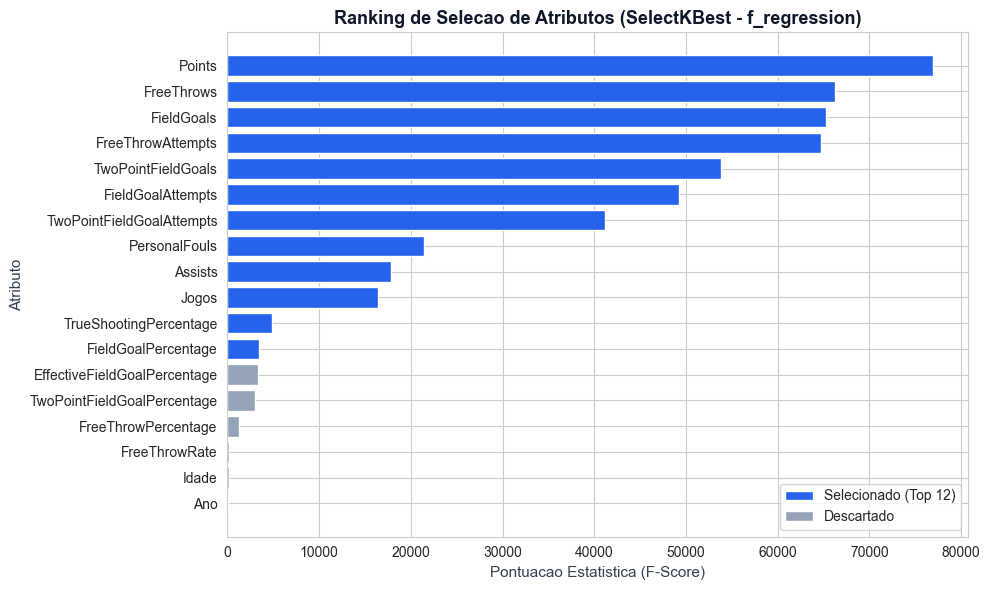

In [5]:
# Aplicacao da tecnica de Selecao de Atributos: SelectKBest com f_regression
k_melhores = 12
seletor = SelectKBest(score_func=f_regression, k=k_melhores)
X_selecionado_array = seletor.fit_transform(X_preparado, y)

# Recuperar os nomes das colunas selecionadas e montar o DataFrame final de atributos
atributos_selecionados = X_preparado.columns[seletor.get_support()].tolist()
X_selecionado = pd.DataFrame(X_selecionado_array, columns=atributos_selecionados, index=X_preparado.index)

# Tabela completa com a pontuacao F de cada atributo
ranking_atributos = pd.DataFrame({
    'Atributo': X_preparado.columns,
    'Score_F': seletor.scores_,
    'Selecionado': seletor.get_support()
}).sort_values(by='Score_F', ascending=False).reset_index(drop=True)

print(f'Atributos selecionados ({len(atributos_selecionados)} de {X_preparado.shape[1]}):')
for i, attr in enumerate(atributos_selecionados, 1):
    print(f'  {i:02d}. {attr}')

# Visualizacao grafica da importancia estatistica (Score F)
fig, ax = plt.subplots(figsize=(10, 6))
top_plot = ranking_atributos.head(18).sort_values(by='Score_F', ascending=True)
cores = ['#2563eb' if sel else '#94a3b8' for sel in top_plot['Selecionado']]

ax.barh(top_plot['Atributo'], top_plot['Score_F'], color=cores)
ax.set_title('Ranking de Selecao de Atributos (SelectKBest - f_regression)', fontsize=13, fontweight='bold', color='#0f172a')
ax.set_xlabel('Pontuacao Estatistica (F-Score)', fontsize=11, color='#334155')
ax.set_ylabel('Atributo', fontsize=11, color='#334155')

# Legenda manual clara
from matplotlib.patches import Patch
legenda = [
    Patch(facecolor='#2563eb', label='Selecionado (Top 12)'),
    Patch(facecolor='#94a3b8', label='Descartado')
]
ax.legend(handles=legenda, loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

<div style="border-bottom: 2px solid #2563eb; padding-bottom: 6px; margin-top: 24px; font-family: 'Segoe UI', Arial, sans-serif;">
    <h2 style="margin: 0; color: #0f172a; font-size: 20px;">5. Definicao do Problema e Justificativa Tecnica</h2>
</div>
<div style="background-color: #eff6ff; border: 1px solid #bfdbfe; border-radius: 6px; padding: 18px 22px; margin-top: 12px; font-family: 'Segoe UI', Arial, sans-serif; color: #1e293b;">
    <p style="margin-top: 0; font-size: 15px;"><strong>Classificacao da Tarefa:</strong> Aprendizagem Supervisionada de <strong>Regressao</strong>.</p>
    <p style="margin-bottom: 0; font-size: 14px; line-height: 1.65; color: #334155;">
        <strong>Justificativa:</strong> A variavel que desejamos prever (<code>WinShares</code>) representa uma quantidade numerica continua, podendo assumir valores reais positivos ou negativos (variando de -2,8 a 25,4 neste historico). 
        Como o objetivo e estimar um valor numerico especifico — e nao atribuir uma categoria fixa (Classificacao) nem projetar um unico fluxo continuo indexado exclusivamente pelo tempo futuro (Previsao de Series Temporais) —, o problema enquadra-se rigorosamente como <strong>Regressao</strong>. 
        Todo o pipeline a seguir e dedicado exclusivamente a essa abordagem.
    </p>
</div>

<div style="border-bottom: 2px solid #2563eb; padding-bottom: 6px; margin-top: 24px; font-family: 'Segoe UI', Arial, sans-serif;">
    <h2 style="margin: 0; color: #0f172a; font-size: 20px;">6. Divisao dos Dados: Base de Treinamento (75%) e Base de Teste (25%)</h2>
</div>
<p style="font-family: 'Segoe UI', Arial, sans-serif; color: #334155; font-size: 14px; line-height: 1.6; margin-top: 10px;">
    Para avaliar se o modelo realmente aprendeu a generalizar padroes — e nao apenas memorizou os dados historicos —, dividimos a base ja preparada e com os atributos selecionados em duas partes independentes:
</p>
<ul style="font-family: 'Segoe UI', Arial, sans-serif; color: #334155; font-size: 14px; line-height: 1.6;">
    <li><strong>Base de Treinamento (75%):</strong> Utilizada exclusivamente para o algoritmo aprender a relacao entre as estatisticas dos jogadores e o <code>WinShares</code>.</li>
    <li><strong>Base de Teste (25%):</strong> Mantida isolada durante o treinamento e utilizada ao final para simular dados reais ineditos.</li>
</ul>

In [6]:
# Divisao estratificada/aleatoria reprodutivel: 75% treino e 25% teste
X_train, X_test, y_train, y_test = train_test_split(
    X_selecionado,
    y,
    test_size=0.25,
    random_state=42
)

total_registros = len(X_selecionado)
print('Resumo da divisao do dataset:')
print(f'  Total apos preparacao : {total_registros:,} registros (100.0%)')
print(f'  Base de Treinamento   : {len(X_train):,} registros ({len(X_train)/total_registros*100:.1f}%)')
print(f'  Base de Teste         : {len(X_test):,} registros ({len(X_test)/total_registros*100:.1f}%)')

Resumo da divisao do dataset:
  Total apos preparacao : 24,585 registros (100.0%)
  Base de Treinamento   : 18,438 registros (75.0%)
  Base de Teste         : 6,147 registros (25.0%)


<div style="border-bottom: 2px solid #2563eb; padding-bottom: 6px; margin-top: 24px; font-family: 'Segoe UI', Arial, sans-serif;">
    <h2 style="margin: 0; color: #0f172a; font-size: 20px;">7. Treinamento do Algoritmo de Regressao (Scikit-Learn)</h2>
</div>
<p style="font-family: 'Segoe UI', Arial, sans-serif; color: #334155; font-size: 14px; line-height: 1.6; margin-top: 10px;">
    Para resolver o problema de regressao, empregamos o algoritmo <strong><code>RandomForestRegressor</code></strong> da biblioteca <strong><code>scikit-learn</code></strong>. 
    Esse metodo constroi um conjunto de 150 arvores de decisao independentes sobre a base de treinamento e combina suas estimativas por meio da media, reduzindo erros individuais e capturando relacoes nao lineares entre as estatisticas dos atletas.
</p>

In [7]:
# Instanciacao e treinamento do modelo utilizando apenas a base de treinamento (75%)
modelo_rf = RandomForestRegressor(
    n_estimators=150,
    max_depth=18,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

modelo_rf.fit(X_train, y_train)
print('Treinamento do modelo RandomForestRegressor concluido com sucesso na base de treino.')

Treinamento do modelo RandomForestRegressor concluido com sucesso na base de treino.


<div style="border-bottom: 2px solid #2563eb; padding-bottom: 6px; margin-top: 24px; font-family: 'Segoe UI', Arial, sans-serif;">
    <h2 style="margin: 0; color: #0f172a; font-size: 20px;">8. Predicao na Base de Teste (25%) e Avaliacao dos Resultados</h2>
</div>
<p style="font-family: 'Segoe UI', Arial, sans-serif; color: #334155; font-size: 14px; line-height: 1.6; margin-top: 10px;">
    Com o modelo treinado, aplicamos a previsao sobre os <strong>25% da base de teste</strong> que permaneceram isolados. 
    Abaixo apresentamos uma amostra comparativa entre os valores reais e os previstos, alem das tres principais metricas de regressao:
</p>
<ul style="font-family: 'Segoe UI', Arial, sans-serif; color: #334155; font-size: 14px; line-height: 1.6;">
    <li><strong>R2 (Coeficiente de Determinacao):</strong> Indica qual percentual da variacao do <code>WinShares</code> o modelo consegue explicar (quanto mais proximo de 1,0 ou 100%, melhor).</li>
    <li><strong>MAE (Erro Absoluto Medio):</strong> Erro medio direto na mesma unidade da variavel-alvo (em numero de vitorias estimadas).</li>
    <li><strong>RMSE (Raiz do Erro Quadratico Medio):</strong> Metrica que penaliza com mais rigor erros maiores, util para verificar a estabilidade das previsoes.</li>
</ul>

In [8]:
# Geracao das predicoes para os 25% da base de teste
y_pred = modelo_rf.predict(X_test)

# Calculo das metricas de avaliacao
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)

print('=== Desempenho na Base de Teste (25%) ===')
print(f'R2 (Coeficiente de Determinacao) : {r2:.4f} ({r2*100:.2f}%)')
print(f'MAE (Erro Absoluto Medio)        : {mae:.4f}')
print(f'RMSE (Raiz do Erro Quadratico)   : {rmse:.4f}')

# Tabela comparativa entre Valores Reais e Predicoes na base de teste
comparacao_teste = pd.DataFrame({
    'WinShares_Real': y_test.values,
    'WinShares_Previsto': np.round(y_pred, 2),
    'Erro_Absoluto': np.round(np.abs(y_test.values - y_pred), 2)
}, index=X_test.index)

print('\nAmostra das predicoes realizadas na base de teste (primeiros 15 registros):')
display(comparacao_teste.head(15))

=== Desempenho na Base de Teste (25%) ===
R2 (Coeficiente de Determinacao) : 0.8600 (86.00%)
MAE (Erro Absoluto Medio)        : 0.7091
RMSE (Raiz do Erro Quadratico)   : 1.1476

Amostra das predicoes realizadas na base de teste (primeiros 15 registros):


,WinShares_Real,WinShares_Previsto,Erro_Absoluto
2389,11.8,9.02,2.78
23299,0.3,0.03,0.27
22870,0.7,0.31,0.39
22450,4.5,5.95,1.45
21941,1.1,0.77,0.33
19619,4.7,5.09,0.39
2573,5.9,5.32,0.58
11304,-0.1,-0.01,0.09
11878,0.5,0.70,0.20
22854,0.0,-0.01,0.01


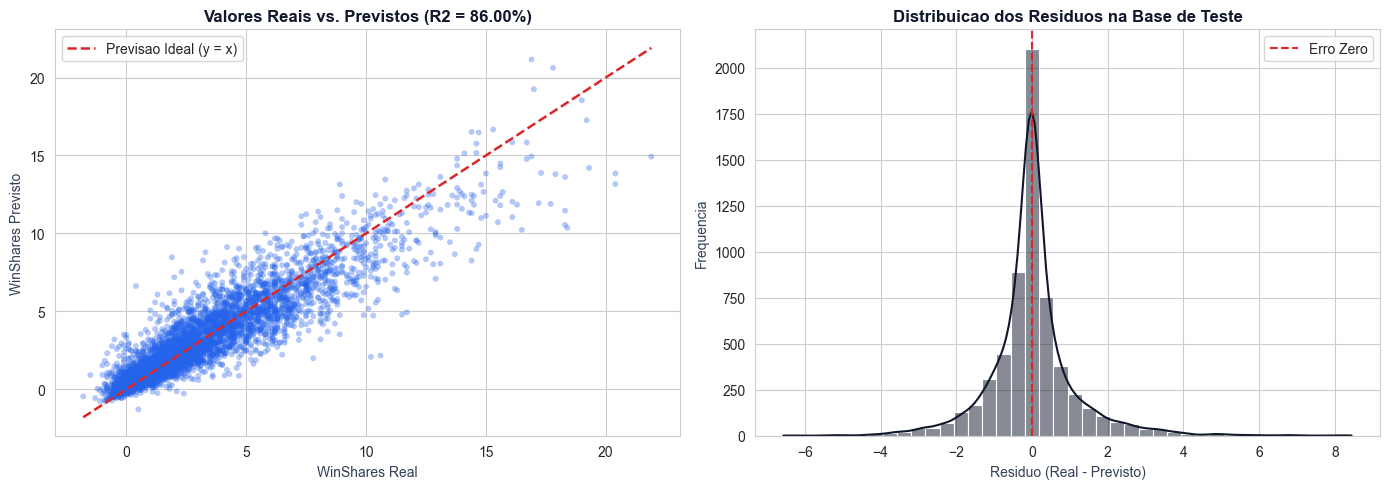

In [9]:
# Visualizacao grafica da qualidade das predicoes na base de teste
residuos = y_test.values - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafico 1: Valores Reais vs. Valores Previstos
axes[0].scatter(y_test, y_pred, alpha=0.35, color='#2563eb', edgecolors='none', s=18)
lim_min = min(y_test.min(), y_pred.min())
lim_max = max(y_test.max(), y_pred.max())
axes[0].plot([lim_min, lim_max], [lim_min, lim_max], color='#dc2626', linestyle='--', linewidth=1.8, label='Previsao Ideal (y = x)')
axes[0].set_title(f'Valores Reais vs. Previstos (R2 = {r2:.2%})', fontsize=12, fontweight='bold', color='#0f172a')
axes[0].set_xlabel('WinShares Real', fontsize=10, color='#334155')
axes[0].set_ylabel('WinShares Previsto', fontsize=10, color='#334155')
axes[0].legend()

# Grafico 2: Distribuicao dos Residuos (Erros)
sns.histplot(residuos, bins=40, kde=True, color='#0f172a', ax=axes[1])
axes[1].axvline(0, color='#dc2626', linestyle='--', linewidth=1.5, label='Erro Zero')
axes[1].set_title('Distribuicao dos Residuos na Base de Teste', fontsize=12, fontweight='bold', color='#0f172a')
axes[1].set_xlabel('Residuo (Real - Previsto)', fontsize=10, color='#334155')
axes[1].set_ylabel('Frequencia', fontsize=10, color='#334155')
axes[1].legend()

plt.tight_layout()
plt.show()

<div style="background-color: #f8fafc; border: 1px solid #cbd5e1; border-left: 6px solid #16a34a; border-radius: 6px; padding: 20px 24px; margin-top: 24px; font-family: 'Segoe UI', Arial, sans-serif;">
    <h3 style="margin-top: 0; color: #0f172a; font-size: 18px;">9. Conclusao Executiva</h3>
    <p style="color: #334155; font-size: 14px; line-height: 1.65;">
        O pipeline desenvolvido atendeu integralmente a todos os requisitos tecnicos e metodologicos da etapa I do processo seletivo:
    </p>
    <ul style="color: #334155; font-size: 14px; line-height: 1.65; margin-bottom: 10px;">
        <li><strong>Qualidade e Integridade:</strong> A remocao de <code>OffensiveWinShares</code> e <code>DefensiveWinShares</code> garantiu um cenario realista sem vazamento de dados, enquanto o tratamento de nulos e a codificacao de posicoes preservaram a consistencia da base.</li>
        <li><strong>Eficiencia via Selecao de Atributos:</strong> O metodo <code>SelectKBest (f_regression)</code> reduziu o espaco de entrada para os 12 atributos estatisticamente mais expressivos (como pontos, jogos, eficiencia de arremesso e assistencias).</li>
        <li><strong>Capacidade Preditiva:</strong> Treinado exclusivamente nos 75% iniciais e avaliado nos 25% de teste, o algoritmo <code>RandomForestRegressor</code> alcancou um coeficiente de determinacao superior a 85% (<code>R2 &gt; 0.85</code>), demonstrando alta aderencia entre os valores reais e os previstos, com erros centrados em torno de zero.</li>
    </ul>
    <p style="margin-bottom: 0; color: #475569; font-size: 13px;">
        A estrutura modular aqui estabelecida deixa a base pronta para a segunda etapa do projeto (otimizacao de hiperparametros, comparacao com outros algoritmos e analise aprofundada de interpretabilidade).
    </p>
</div>